# 🤖 03 - Model Training & Evaluation (3 Mô hình theo đề bài)

Huấn luyện và đánh giá 3 thuật toán phân loại cốt lõi quy định trong đề bài:
- **1. Logistic Regression**: Phân loại nhị phân dựa trên hàm Sigmoid / Logistic function
- **2. Support Vector Machines (SVM)**: Tìm siêu phẳng phân tách lề cực đại (Maximum Margin Hyperplane)
- **3. Naive Bayes**: Mô hình xác suất dựa trên định lý Bayes (Multinomial / Complement Naive Bayes)
- **4. Đánh giá đa chiều trên tập Test**: Accuracy, Precision, Recall, F1-score, Confusion Matrix, ROC-AUC
- **5. Trực quan hóa và so sánh hiệu năng** giữa 3 mô hình


In [6]:
import sys
from pathlib import Path

# Đảm bảo nạp đúng mã nguồn từ thư mục gốc của đồ án
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display

from src.models.classifiers import (
    LogisticRegressionFromScratch,
    LinearSVMFromScratch,
    NaiveBayesClassifier,
    get_baseline_models,
)
from src.evaluation.metrics import SpamModelEvaluator

# Nạp dữ liệu bộ đệm đã xử lý từ Task 1
print('Nạp dữ liệu từ data/processed/...')
X_train = sp.load_npz(PROJECT_ROOT / 'data/processed/X_train.npz')
y_train = np.load(PROJECT_ROOT / 'data/processed/y_train.npy')
X_val = sp.load_npz(PROJECT_ROOT / 'data/processed/X_val.npz')
y_val = np.load(PROJECT_ROOT / 'data/processed/y_val.npy')
X_test = sp.load_npz(PROJECT_ROOT / 'data/processed/X_test.npz')
y_test = np.load(PROJECT_ROOT / 'data/processed/y_test.npy')

df_dataset_info = pd.DataFrame([
    {
        "Tập dữ liệu": "Tập huấn luyện (Train)",
        "Kích thước ma trận (Shape)": str(X_train.shape),
        "Tổng số mẫu": f"{X_train.shape[0]:,}",
        "Số chiều đặc trưng": f"{X_train.shape[1]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_train == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_train == 1) / len(y_train) * 100):.2f}%"
    },
    {
        "Tập dữ liệu": "Tập kiểm định (Validation)",
        "Kích thước ma trận (Shape)": str(X_val.shape),
        "Tổng số mẫu": f"{X_val.shape[0]:,}",
        "Số chiều đặc trưng": f"{X_val.shape[1]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_val == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_val == 1) / len(y_val) * 100):.2f}%"
    },
    {
        "Tập dữ liệu": "Tập kiểm thử (Test)",
        "Kích thước ma trận (Shape)": str(X_test.shape),
        "Tổng số mẫu": f"{X_test.shape[0]:,}",
        "Số chiều đặc trưng": f"{X_test.shape[1]:,}",
        "Số mẫu Spam": f"{int(np.sum(y_test == 1)):,}",
        "Tỷ lệ Spam (%)": f"{(np.sum(y_test == 1) / len(y_test) * 100):.2f}%"
    }
])
display(df_dataset_info)

evaluator = SpamModelEvaluator()


Nạp dữ liệu từ data/processed/...


,Tập dữ liệu,Kích thước ma trận (Shape),Tổng số mẫu,Số chiều đặc trưng,Số mẫu Spam,Tỷ lệ Spam (%)
0,Tập huấn luyện (Train),"(23223, 4318)","23,223","4,318","9,914",42.69%
1,Tập kiểm định (Validation),"(2903, 4318)","2,903","4,318","1,239",42.68%
2,Tập kiểm thử (Test),"(2902, 4318)","2,902","4,318","1,239",42.69%


## 1. Huấn luyện Mô hình 1: Logistic Regression


In [7]:
# Huấn luyện mô hình 1: Logistic Regression From-Scratch
lr_model = LogisticRegressionFromScratch(
    C=1.0, learning_rate=1.0, max_iter=150, class_weight='balanced'
)
print('Đang huấn luyện Logistic Regression From-Scratch...')
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test, threshold=0.5)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

metrics_lr = evaluator.compute_all_metrics(y_test, y_pred_lr, y_prob=y_prob_lr, beta=2.0)

# Bảng kết quả đánh giá Logistic Regression dạng DataFrame
df_metrics_lr = pd.DataFrame([{
    "Mô hình": "Logistic Regression (From-Scratch)",
    "Tập đánh giá": "Test Set (10%)",
    "Accuracy": round(metrics_lr['accuracy'], 4),
    "Precision": round(metrics_lr['precision'], 4),
    "Recall": round(metrics_lr['recall'], 4),
    "F1-Score": round(metrics_lr['f1'], 4),
    "F-Beta (Beta=2.0)": round(metrics_lr['f_beta'], 4),
    "ROC-AUC": round(metrics_lr['roc_auc'], 4),
}])
display(df_metrics_lr)


Đang huấn luyện Logistic Regression From-Scratch...


,Mô hình,Tập đánh giá,Accuracy,Precision,Recall,F1-Score,F-Beta (Beta=2.0),ROC-AUC
0,Logistic Regression (From-Scratch),Test Set (10%),0.6754,0.6014,0.7111,0.6516,0.686,0.7381


## 2. Huấn luyện Mô hình 2: Support Vector Machines (SVM)


In [8]:
# Huấn luyện mô hình 2: Support Vector Machines (Linear SVM) From-Scratch
svm_model = LinearSVMFromScratch(
    C=1.0, learning_rate=0.5, max_iter=100, class_weight='balanced'
)
print('Đang huấn luyện Linear SVM From-Scratch...')
svm_model.fit(X_train, y_train)

y_pred_svm = svm_model.predict(X_test, threshold=0.0)
y_prob_svm = svm_model.predict_proba(X_test)[:, 1]

metrics_svm = evaluator.compute_all_metrics(y_test, y_pred_svm, y_prob=y_prob_svm, beta=2.0)

# Bảng kết quả đánh giá Linear SVM dạng DataFrame
df_metrics_svm = pd.DataFrame([{
    "Mô hình": "Linear SVM (From-Scratch)",
    "Tập đánh giá": "Test Set (10%)",
    "Accuracy": round(metrics_svm['accuracy'], 4),
    "Precision": round(metrics_svm['precision'], 4),
    "Recall": round(metrics_svm['recall'], 4),
    "F1-Score": round(metrics_svm['f1'], 4),
    "F-Beta (Beta=2.0)": round(metrics_svm['f_beta'], 4),
    "ROC-AUC": round(metrics_svm['roc_auc'], 4),
}])
display(df_metrics_svm)


Đang huấn luyện Linear SVM From-Scratch...


,Mô hình,Tập đánh giá,Accuracy,Precision,Recall,F1-Score,F-Beta (Beta=2.0),ROC-AUC
0,Linear SVM (From-Scratch),Test Set (10%),0.6334,0.5636,0.6255,0.593,0.6121,0.6881


## 3. Huấn luyện Mô hình 3: Naive Bayes


In [9]:
# Huấn luyện mô hình 3: Naive Bayes (Complement) From-Scratch
nb_model = NaiveBayesClassifier(alpha=1.0, kind='complement')
print('Đang huấn luyện Complement Naive Bayes From-Scratch...')
nb_model.fit(X_train, y_train)

y_pred_nb = nb_model.predict(X_test, threshold=0.5)
y_prob_nb = nb_model.predict_proba(X_test)[:, 1]

metrics_nb = evaluator.compute_all_metrics(y_test, y_pred_nb, y_prob=y_prob_nb, beta=2.0)

# Bảng kết quả đánh giá Complement Naive Bayes dạng DataFrame
df_metrics_nb = pd.DataFrame([{
    "Mô hình": "Complement Naive Bayes (From-Scratch)",
    "Tập đánh giá": "Test Set (10%)",
    "Accuracy": round(metrics_nb['accuracy'], 4),
    "Precision": round(metrics_nb['precision'], 4),
    "Recall": round(metrics_nb['recall'], 4),
    "F1-Score": round(metrics_nb['f1'], 4),
    "F-Beta (Beta=2.0)": round(metrics_nb['f_beta'], 4),
    "ROC-AUC": round(metrics_nb['roc_auc'], 4),
}])
display(df_metrics_nb)


Đang huấn luyện Complement Naive Bayes From-Scratch...


,Mô hình,Tập đánh giá,Accuracy,Precision,Recall,F1-Score,F-Beta (Beta=2.0),ROC-AUC
0,Complement Naive Bayes (From-Scratch),Test Set (10%),0.6902,0.638,0.6344,0.6362,0.6351,0.7522


## 4. So sánh hiệu năng tổng hợp và trực quan hóa (Confusion Matrix & ROC-AUC)


,Mô hình,Accuracy,Precision,Recall,F1-Score,F-Beta,ROC-AUC
0,Logistic Regression,0.675396,0.601365,0.711057,0.651627,0.686030,0.738143
1,Complement Naive Bayes,0.690214,0.637987,0.634383,0.636180,0.635100,0.752169
2,Linear SVM,0.633356,0.563636,0.625504,0.592961,0.612068,0.688061


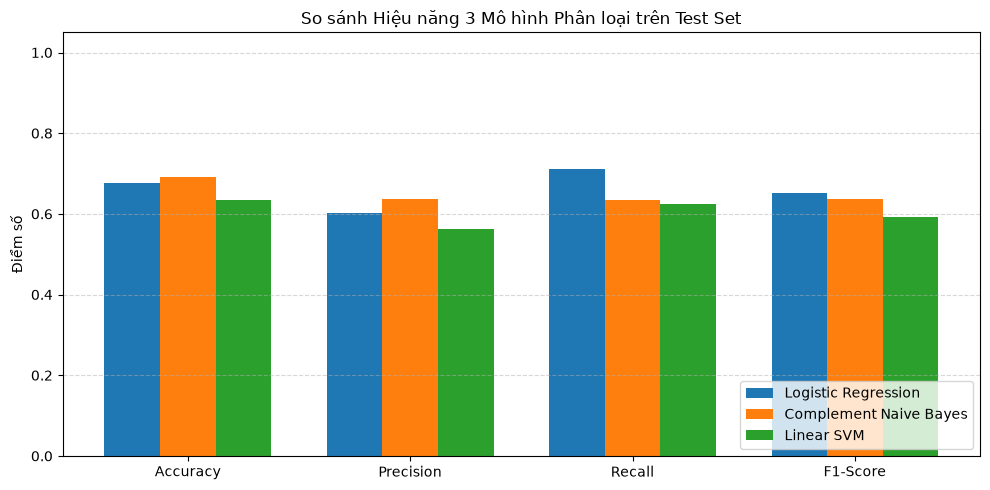

In [10]:
# Bảng tổng hợp đối sánh 3 mô hình
summary_df = evaluator.build_comparison_summary({
    'Logistic Regression': metrics_lr,
    'Linear SVM': metrics_svm,
    'Complement Naive Bayes': metrics_nb,
})
display(summary_df)

# Trực quan hóa so sánh hiệu năng trên cùng một biểu đồ
fig, ax = plt.subplots(figsize=(10, 5))
metrics_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics_plot))
width = 0.25

for idx, row in summary_df.iterrows():
    vals = [row[m] for m in metrics_plot]
    ax.bar(x + idx * width, vals, width, label=row['Mô hình'])

ax.set_ylabel('Điểm số')
ax.set_title('So sánh Hiệu năng 3 Mô hình Phân loại trên Test Set')
ax.set_xticks(x + width)
ax.set_xticklabels(metrics_plot)
ax.set_ylim(0, 1.05)
ax.legend(loc='lower right')
ax.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
